In [3]:
import sys
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector")

sys.path.append(str(PROJECT_DIR))

print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())
print("src exists:", (PROJECT_DIR / "src").exists())

Project directory: C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector
Project exists: True
src exists: True


In [4]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\deepfake-env\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [5]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\deepfake-env\Scripts\python.exe
PyTorch: 2.5.1+cu121
CUDA available: True
GPU: NVIDIA GeForce RTX 2050


In [6]:
import pandas as pd

from src.config import TRAIN_CSV, VALID_CSV, TEST_CSV, DATA_ROOT

# Load the CSV files
train_df = pd.read_csv(TRAIN_CSV)
valid_df = pd.read_csv(VALID_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

Train: 100000
Validation: 20000
Test: 20000


In [7]:
train_df["full_path"] = train_df["path"].apply(
    lambda x: DATA_ROOT / x
)

valid_df["full_path"] = valid_df["path"].apply(
    lambda x: DATA_ROOT / x
)

test_df["full_path"] = test_df["path"].apply(
    lambda x: DATA_ROOT / x
)

print(train_df[["path", "full_path", "label"]].head())

                   path                                          full_path  \
0  train/real/31355.jpg  C:\Users\mda16\Downloads\Dataset\real_vs_fake\...   
1  train/real/02884.jpg  C:\Users\mda16\Downloads\Dataset\real_vs_fake\...   
2  train/real/33988.jpg  C:\Users\mda16\Downloads\Dataset\real_vs_fake\...   
3  train/real/53875.jpg  C:\Users\mda16\Downloads\Dataset\real_vs_fake\...   
4  train/real/24149.jpg  C:\Users\mda16\Downloads\Dataset\real_vs_fake\...   

   label  
0      1  
1      1  
2      1  
3      1  
4      1  


In [12]:
from src.transforms import train_transform, valid_test_transform

In [13]:
from src.dataset import FaceDataset

train_dataset = FaceDataset(
    dataframe=train_df,
    transform=train_transform
)

valid_dataset = FaceDataset(
    dataframe=valid_df,
    transform=valid_test_transform
)

test_dataset = FaceDataset(
    dataframe=test_df,
    transform=valid_test_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(valid_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 100000
Validation dataset: 20000
Test dataset: 20000


In [14]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Train batches: 6250
Validation batches: 1250
Test batches: 1250


In [15]:
# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

# Move the batch to the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

images = images.to(device)
labels = labels.to(device)

print("Device:", device)
print("Images device:", images.device)
print("Labels device:", labels.device)

Images shape: torch.Size([16, 3, 128, 128])
Labels shape: torch.Size([16])
Device: cuda
Images device: cuda:0
Labels device: cuda:0


In [16]:
from src.model import BasicCNN

# Create the model
model = BasicCNN(num_classes=2)

# Move the model to the GPU
model = model.to(device)

print(model)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): LazyLinear(in_features=0, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [17]:
# Run one batch through the model
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Outputs:")
print(outputs)

Input shape: torch.Size([16, 3, 128, 128])
Output shape: torch.Size([16, 2])
Outputs:
tensor([[ 0.1129,  0.0892],
        [ 0.0890, -0.0039],
        [ 0.1368,  0.0469],
        [ 0.1381,  0.0009],
        [ 0.0482,  0.0165],
        [ 0.0950,  0.0154],
        [ 0.0659, -0.0099],
        [ 0.1769,  0.0118],
        [ 0.0913, -0.0116],
        [ 0.0500,  0.0145],
        [ 0.0836, -0.0179],
        [ 0.1074, -0.0189],
        [ 0.0868,  0.0044],
        [ 0.1211,  0.0649],
        [ 0.1407, -0.0286],
        [ 0.1091, -0.0221]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [18]:
print("Label mapping:")
print(train_df[["label", "label_str"]].drop_duplicates().sort_values("label"))

Label mapping:
       label label_str
50000      0      fake
0          1      real


In [19]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [20]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [21]:
# Get one fresh training batch
images, labels = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
labels = labels.to(device)

# Training mode
model.train()

# Clear old gradients
optimizer.zero_grad()

# Forward pass
outputs = model(images)

# Calculate loss
loss = criterion(outputs, labels)

# Backpropagation
loss.backward()

# Update model weights
optimizer.step()

print("Batch loss:", loss.item())
print("Training step completed successfully.")

Batch loss: 0.6983373165130615
Training step completed successfully.


In [22]:
from src.model import BasicCNN

# Start with a completely fresh model
model = BasicCNN(num_classes=2).to(device)

# Recreate the loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh model created.")
print("Device:", device)

Fresh model created.
Device: cuda


In [23]:
import time
from tqdm import tqdm

# Start timing the epoch
start_time = time.time()

model.train()

running_loss = 0.0
correct = 0
total = 0

# -------------------------
# Training
# -------------------------
for images, labels in tqdm(train_loader, desc="Training"):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    # Track loss
    running_loss += loss.item()

    # Track accuracy
    predictions = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predictions == labels).sum().item()

# Calculate training metrics
train_loss = running_loss / len(train_loader)
train_accuracy = 100 * correct / total


# -------------------------
# Validation
# -------------------------
model.eval()

val_running_loss = 0.0
val_correct = 0
val_total = 0

with torch.no_grad():

    for images, labels in tqdm(valid_loader, desc="Validation"):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        val_total += labels.size(0)
        val_correct += (predictions == labels).sum().item()


# Calculate validation metrics
val_loss = val_running_loss / len(valid_loader)
val_accuracy = 100 * val_correct / val_total


# -------------------------
# Results
# -------------------------
epoch_time = time.time() - start_time

print("\nEpoch 1 Results")
print("-------------------------")
print(f"Training Loss:   {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")
print(f"Epoch Time: {epoch_time / 60:.2f} minutes")

Validation: 100%|██████████| 1250/1250 [07:48<00:00,  2.67it/s]


Epoch 1 Results
-------------------------
Training Loss:   0.5853
Training Accuracy: 68.75%
Validation Loss: 0.5114
Validation Accuracy: 75.41%
Epoch Time: 47.05 minutes


In [24]:
from torch.utils.data import DataLoader

# Create a faster training DataLoader
train_loader_test = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader_test))
print("Workers:", train_loader_test.num_workers)

Train batches: 6250
Workers: 2


In [25]:
import time

# Benchmark 200 batches
start_time = time.time()

for batch_index, (images, labels) in enumerate(train_loader_test):

    if batch_index + 1 == 200:
        break

elapsed = time.time() - start_time

print(f"Time for 200 batches: {elapsed:.2f} seconds")
print(f"Average time per batch: {elapsed / 200:.3f} seconds")
print(f"Estimated training-data time for one epoch: {elapsed / 200 * len(train_loader_test) / 60:.2f} minutes")

Time for 200 batches: 28.55 seconds
Average time per batch: 0.143 seconds
Estimated training-data time for one epoch: 14.87 minutes


In [26]:
train_loader_32 = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Test one batch
images_32, labels_32 = next(iter(train_loader_32))

images_32 = images_32.to(device)
labels_32 = labels_32.to(device)

print("Images shape:", images_32.shape)
print("Labels shape:", labels_32.shape)
print("GPU memory allocated:",
      torch.cuda.memory_allocated() / 1024**3, "GB")

Images shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])
GPU memory allocated: 0.08563041687011719 GB


In [27]:
import time
from tqdm import tqdm

model.train()

start_time = time.time()

for batch_index, (images, labels) in enumerate(
    tqdm(train_loader_32, desc="Benchmarking")
):

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    if batch_index + 1 == 100:
        break

elapsed = time.time() - start_time

print("\nBenchmark Results")
print("-------------------------")
print(f"100 batches time: {elapsed:.2f} seconds")
print(f"Average time per batch: {elapsed / 100:.3f} seconds")
print(
    f"Estimated training time for one epoch: "
    f"{(elapsed / 100) * len(train_loader_32) / 60:.2f} minutes"
)
print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)
print(
    f"GPU memory reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

Benchmarking:   3%|▎         | 99/3125 [00:24<12:35,  4.01it/s]  


Benchmark Results
-------------------------
100 batches time: 24.71 seconds
Average time per batch: 0.247 seconds
Estimated training time for one epoch: 12.87 minutes
GPU memory allocated: 0.09 GB
GPU memory reserved: 0.47 GB


In [28]:
from src.model import BasicCNN
import torch.nn as nn
import torch.optim as optim

# Create a completely fresh model
model = BasicCNN(num_classes=2).to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh model created.")
print("Device:", device)
print("Optimizer:", optimizer)

Fresh model created.
Device: cuda
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [30]:
from src.config import MODEL_DIR

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR)
print("Exists:", MODEL_DIR.exists())

Model directory: C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\models
Exists: True


In [31]:
from src.model import BasicCNN
import torch.nn as nn
import torch.optim as optim

# Fresh model
model = BasicCNN(num_classes=2).to(device)

# Fresh loss function
criterion = nn.CrossEntropyLoss()

# Fresh optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Reset training history
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0

print("Model reset successfully.")
print("Device:", device)
print("Best validation accuracy reset to:", best_val_accuracy)

Model reset successfully.
Device: cuda
Best validation accuracy reset to: 0.0


In [32]:
# Test that the checkpoint directory is writable

test_path = MODEL_DIR / "test_checkpoint.pth"

torch.save(
    model.state_dict(),
    test_path
)

print("Checkpoint test successful.")
print("Saved to:", test_path)

# Remove the temporary test checkpoint
test_path.unlink()

print("Temporary checkpoint removed.")

Checkpoint test successful.
Saved to: C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\models\test_checkpoint.pth
Temporary checkpoint removed.


In [33]:
import time
from tqdm import tqdm
import torch


# ============================================================
# TRAINING SETTINGS
# ============================================================

num_epochs = 10

# Training history
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

# Best validation accuracy seen so far
best_val_accuracy = 0.0


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(num_epochs):

    epoch_start = time.time()

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_progress = tqdm(
        train_loader_32,
        desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
    )

    for images, labels in train_progress:

        # Move data to GPU
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Calculate predictions
        predictions = outputs.argmax(dim=1)

        # Track accuracy
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    # Calculate average training metrics
    train_loss = running_loss / len(train_loader_32)
    train_accuracy = 100 * correct / total


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    val_progress = tqdm(
        valid_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
    )

    with torch.no_grad():

        for images, labels in val_progress:

            # Move data to GPU
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Track loss
            val_running_loss += loss.item()

            # Calculate predictions
            predictions = outputs.argmax(dim=1)

            # Track accuracy
            val_total += labels.size(0)
            val_correct += (predictions == labels).sum().item()

    # Calculate average validation metrics
    val_loss = val_running_loss / len(valid_loader)
    val_accuracy = 100 * val_correct / val_total


    # --------------------------------------------------------
    # STORE HISTORY
    # --------------------------------------------------------

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": val_accuracy,
            "val_loss": val_loss
        }

        torch.save(
            checkpoint,
            MODEL_DIR / "best_basic_cnn.pth"
        )

        best_model_saved = True

    else:

        best_model_saved = False


    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    epoch_time = time.time() - epoch_start

    print()
    print("=" * 60)
    print(f"Epoch {epoch + 1}/{num_epochs}")
    print("=" * 60)

    print(f"Training Loss:        {train_loss:.4f}")
    print(f"Training Accuracy:    {train_accuracy:.2f}%")
    print(f"Validation Loss:      {val_loss:.4f}")
    print(f"Validation Accuracy:  {val_accuracy:.2f}%")
    print(f"Best Validation Acc:  {best_val_accuracy:.2f}%")
    print(f"Epoch Time:           {epoch_time / 60:.2f} minutes")

    if best_model_saved:
        print("✓ Best model saved")

    print("=" * 60)

Epoch 1/10 - Validation: 100%|██████████| 1250/1250 [01:55<00:00, 10.85it/s]



Epoch 1/10
Training Loss:        0.5746
Training Accuracy:    69.92%
Validation Loss:      0.4998
Validation Accuracy:  76.41%
Best Validation Acc:  76.41%
Epoch Time:           5.28 minutes
✓ Best model saved


Epoch 2/10 - Validation: 100%|██████████| 1250/1250 [01:54<00:00, 10.92it/s]



Epoch 2/10
Training Loss:        0.4781
Training Accuracy:    77.63%
Validation Loss:      0.4156
Validation Accuracy:  80.81%
Best Validation Acc:  80.81%
Epoch Time:           5.49 minutes
✓ Best model saved


Epoch 3/10 - Validation: 100%|██████████| 1250/1250 [01:55<00:00, 10.84it/s]



Epoch 3/10
Training Loss:        0.4226
Training Accuracy:    80.88%
Validation Loss:      0.3727
Validation Accuracy:  83.55%
Best Validation Acc:  83.55%
Epoch Time:           5.34 minutes
✓ Best model saved


... (10 outputs left out)

Epoch 9/10 - Validation: 100%|██████████| 1250/1250 [01:40<00:00, 12.42it/s]



Epoch 9/10
Training Loss:        0.2817
Training Accuracy:    88.35%
Validation Loss:      0.2848
Validation Accuracy:  88.50%
Best Validation Acc:  88.81%
Epoch Time:           4.74 minutes


Epoch 10/10 - Validation: 100%|██████████| 1250/1250 [01:38<00:00, 12.71it/s]


Epoch 10/10
Training Loss:        0.2700
Training Accuracy:    88.95%
Validation Loss:      0.2240
Validation Accuracy:  90.92%
Best Validation Acc:  90.92%
Epoch Time:           4.64 minutes
✓ Best model saved


Matplotlib is building the font cache; this may take a moment.


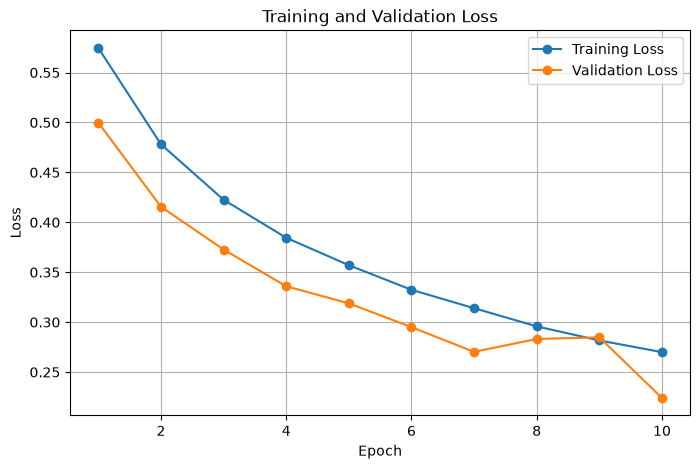

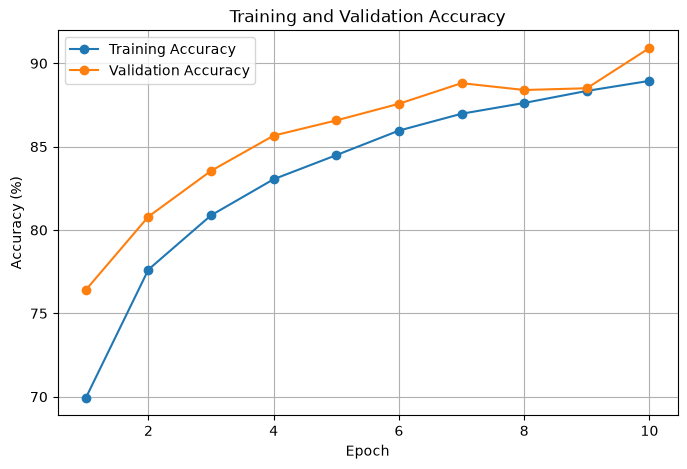

In [34]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Loss curves
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# Accuracy curves
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [35]:
import torch
import numpy as np
from tqdm import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# TEST DATALOADER
# ============================================================

test_loader_32 = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint_path = MODEL_DIR / "best_basic_cnn.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

print("Best checkpoint loaded.")
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {checkpoint['val_accuracy']:.2f}%")
print(f"Validation loss: {checkpoint['val_loss']:.4f}")


# ============================================================
# TEST EVALUATION
# ============================================================

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader_32,
        desc="Testing"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


# Convert to NumPy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)


# ============================================================
# CALCULATE METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)


# ============================================================
# RESULTS
# ============================================================

print()
print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision * 100:.2f}%")
print(f"Test Recall:    {test_recall * 100:.2f}%")
print(f"Test F1 Score:  {test_f1 * 100:.2f}%")

print()
print("Confusion Matrix")
print("-------------------------")
print(cm)

print()
print("Classification Report")
print("-------------------------")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

C:\Users\mda16\AppData\Local\Temp\ipykernel_11912\345612798.py:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


Best checkpoint loaded.
Checkpoint epoch: 10
Validation accuracy: 90.92%
Validation loss: 0.2240


Testing: 100%|██████████| 625/625 [02:46<00:00,  3.76it/s]


FINAL TEST RESULTS
Test Accuracy:  91.20%
Test Precision: 89.07%
Test Recall:    93.92%
Test F1 Score:  91.43%

Confusion Matrix
-------------------------
[[8847 1153]
 [ 608 9392]]

Classification Report
-------------------------
              precision    recall  f1-score   support

        Fake     0.9357    0.8847    0.9095     10000
        Real     0.8907    0.9392    0.9143     10000

    accuracy                         0.9120     20000
   macro avg     0.9132    0.9120    0.9119     20000
weighted avg     0.9132    0.9120    0.9119     20000



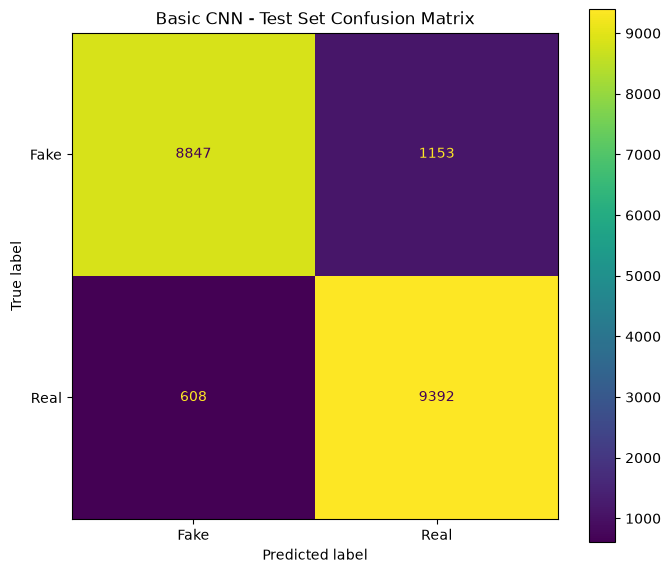

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Basic CNN - Test Set Confusion Matrix")

plt.tight_layout()
plt.show()

In [38]:
from src.config import RESULTS_DIR

# Make sure the results folder exists
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Exists:", RESULTS_DIR.exists())

Results directory: C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\results
Exists: True


In [39]:
import json
import pandas as pd

# ============================================================
# SAVE BASELINE EXPERIMENT RESULTS
# ============================================================

baseline_results = {
    "dataset": "140k Real and Fake Faces",
    "model": "BasicCNN",
    "image_size": "128x128",
    "batch_size": 32,
    "epochs": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,

    "best_epoch": int(checkpoint["epoch"]),

    "validation_accuracy": float(checkpoint["val_accuracy"]),
    "validation_loss": float(checkpoint["val_loss"]),

    "test_accuracy": float(test_accuracy * 100),
    "test_precision_real": float(test_precision * 100),
    "test_recall_real": float(test_recall * 100),
    "test_f1_real": float(test_f1 * 100),

    "test_precision_fake": float(
        precision_score(
            all_labels,
            all_predictions,
            pos_label=0,
            zero_division=0
        ) * 100
    ),

    "test_recall_fake": float(
        recall_score(
            all_labels,
            all_predictions,
            pos_label=0,
            zero_division=0
        ) * 100
    ),

    "test_f1_fake": float(
        f1_score(
            all_labels,
            all_predictions,
            pos_label=0,
            zero_division=0
        ) * 100
    ),

    "macro_f1": float(
        f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        ) * 100
    )
}


# Save metrics as JSON
results_path = RESULTS_DIR / "baseline_results.json"

with open(results_path, "w") as f:
    json.dump(
        baseline_results,
        f,
        indent=4
    )


# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

cm_path = RESULTS_DIR / "baseline_confusion_matrix.csv"

cm_dataframe = pd.DataFrame(
    cm,
    index=["Actual_Fake", "Actual_Real"],
    columns=["Predicted_Fake", "Predicted_Real"]
)

cm_dataframe.to_csv(cm_path)


# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_path = RESULTS_DIR / "baseline_training_history.csv"

history_dataframe = pd.DataFrame({
    "epoch": range(1, len(train_losses) + 1),
    "train_loss": train_losses,
    "train_accuracy": train_accuracies,
    "validation_loss": val_losses,
    "validation_accuracy": val_accuracies
})

history_dataframe.to_csv(
    history_path,
    index=False
)


# ============================================================
# DISPLAY
# ============================================================

print("Baseline experiment saved successfully.")
print()
print("Results:")
print(results_path)
print()
print("Confusion matrix:")
print(cm_path)
print()
print("Training history:")
print(history_path)

Baseline experiment saved successfully.

Results:
C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\results\baseline_results.json

Confusion matrix:
C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\results\baseline_confusion_matrix.csv

Training history:
C:\Users\mda16\OneDrive\Desktop\DeepfakeDetector\results\baseline_training_history.csv
